# Grover search: a runnable three-qubit demo
Install the versions in binder/environment.yml, or launch this notebook in Binder. To run the downloads locally, save grover.py beside this notebook. Source checkouts also work.

This pedagogical equality oracle marks a known integer. It illustrates amplitude amplification; it is not a practical classical search benchmark. Reference: L. K. Grover, *A fast quantum mechanical algorithm for database search* (1996), https://arxiv.org/abs/quant-ph/9605043. We use Qiskit core (Apache-2.0), https://github.com/Qiskit/qiskit.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from qiskit.quantum_info import Statevector
try:
    from openquantum.grover import build_grover_circuit, expected_success_probability, optimal_iterations, decompose_to_rotation_basis
except ModuleNotFoundError:
    sys.path.insert(0, str(root / "notebooks"))
    from grover import build_grover_circuit, expected_success_probability, optimal_iterations, decompose_to_rotation_basis


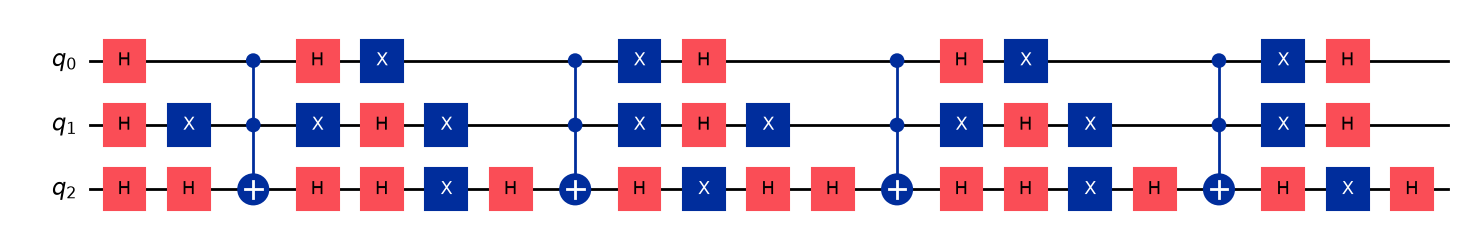

In [2]:
n_qubits, marked = 3, 5
iterations = optimal_iterations(n_qubits)
circuit = build_grover_circuit(n_qubits, marked, iterations)
circuit.draw(output='mpl', fold=32)

In [3]:
probabilities = Statevector.from_instruction(circuit).probabilities_dict()
target = f'{marked:0{n_qubits}b}'
predicted = expected_success_probability(n_qubits, iterations)
print({'target': target, 'iterations': iterations, 'simulated': probabilities[target], 'predicted': predicted})
assert abs(probabilities[target] - predicted) < 1e-10

{'target': '101', 'iterations': 2, 'simulated': np.float64(0.945312499999996), 'predicted': 0.9453124999999999}


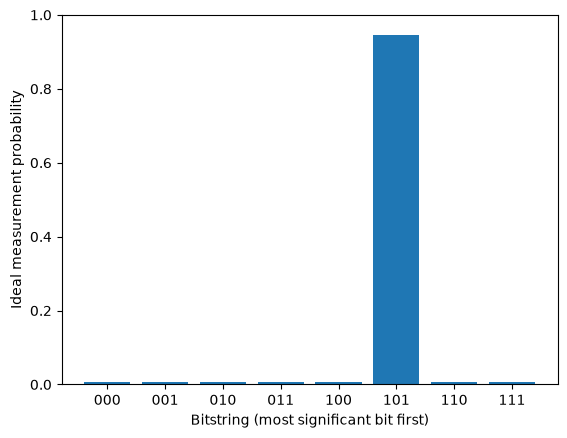

In [4]:
import matplotlib.pyplot as plt
plt.bar(list(probabilities), list(probabilities.values()))
plt.xlabel('Bitstring (most significant bit first)')
plt.ylabel('Ideal measurement probability')
plt.ylim(0, 1)
plt.show()

## Live, bounded exploration

Run the following cells in Binder or a local JupyterLab kernel to use Python controls. The published book shows saved circuit and probability outputs; its separate browser explorer computes the ideal probability formula.

The notebook controls regenerate the actual Qiskit circuit and exact statevector for 2–6 qubits and 0–12 Grover iterations. The marked value adapts to the register size. Every evaluation checks the simulated marked-state probability against the analytic formula.


In [5]:
import os
import numpy as np


def simulate_interactive_case(n_qubits, marked, iterations):
    """Bounded ideal simulation shared by the controls and deterministic checks."""
    if not 2 <= n_qubits <= 6:
        raise ValueError("Live controls support 2–6 qubits")
    if not 0 <= iterations <= 12:
        raise ValueError("Live controls support 0–12 iterations")
    marked = min(max(int(marked), 0), 2**n_qubits - 1)
    circuit = build_grover_circuit(n_qubits, marked, iterations)
    probabilities = Statevector.from_instruction(circuit).probabilities()
    expected = expected_success_probability(n_qubits, iterations)
    np.testing.assert_allclose(probabilities[marked], expected, atol=1e-10, rtol=0)
    return circuit, probabilities, marked, expected


for validation_n in range(2, 7):
    for validation_marked in (0, 2**validation_n - 1):
        for validation_iterations in (0, optimal_iterations(validation_n), 12):
            simulate_interactive_case(validation_n, validation_marked, validation_iterations)
print("Validated 30 bounded cases; every live evaluation also checks the analytic probability.")


Validated 30 bounded cases; every live evaluation also checks the analytic probability.


In [6]:
# The book build skips widget creation so it never publishes inert controls.
# Binder and local kernels display live controls when this cell is run.
if os.environ.get("OPENQUANTUM_STATIC_BUILD") == "1":
    print("Live Python controls are available when this notebook is run in Binder or JupyterLab.")
else:
    import ipywidgets as widgets
    from IPython.display import display

    n_control = widgets.IntSlider(value=3, min=2, max=6, description="Qubits", continuous_update=False)
    marked_control = widgets.IntSlider(value=5, min=0, max=7, description="Marked", continuous_update=False)
    iterations_control = widgets.IntSlider(value=2, min=0, max=12, description="Iterations", continuous_update=False)

    def update_marked_range(change):
        marked_control.max = 2**change["new"] - 1
        marked_control.value = min(marked_control.value, marked_control.max)

    n_control.observe(update_marked_range, names="value")

    def render_live_case(n_qubits, marked, iterations):
        circuit, probabilities, marked, expected = simulate_interactive_case(n_qubits, marked, iterations)
        target = f"{marked:0{n_qubits}b}"
        print(f"Target {target}; {iterations} iterations; first-peak choice {optimal_iterations(n_qubits)}")
        print(f"Statevector probability {probabilities[marked]:.10f}; analytic probability {expected:.10f}")
        print("Ideal circuit: no device noise or fault-tolerant resource model is applied here.")
        circuit_figure = circuit.draw(output="mpl", fold=32, scale=0.65)
        display(circuit_figure)
        plt.close(circuit_figure)
        figure, axis = plt.subplots(figsize=(8, 3.2))
        indices = list(range(len(probabilities)))
        labels = [f"{i:0{n_qubits}b}" for i in indices]
        axis.bar(indices, probabilities, color=["#1c766c" if i == marked else "#b5c6d2" for i in indices])
        ticks = indices if n_qubits <= 4 else sorted({0, marked, len(probabilities) - 1})
        axis.set_xticks(ticks, [labels[i] for i in ticks])
        axis.set(xlabel="Bitstring (most significant bit first)", ylabel="Ideal measurement probability", ylim=(0, 1))
        figure.tight_layout()
        display(figure)
        plt.close(figure)

    live_output = widgets.interactive_output(render_live_case, {
        "n_qubits": n_control, "marked": marked_control, "iterations": iterations_control
    })
    display(widgets.VBox([widgets.HBox([n_control, marked_control, iterations_control]), live_output]))


Live Python controls are available when this notebook is run in Binder or JupyterLab.


## Generate a circuit without simulating it
The next cell generates and decomposes a moderate circuit, then exports OpenQASM 3. It does not allocate a statevector. Arbitrary rotations still need synthesis for a fault-tolerant resource estimate. Fully expanded Grover circuits grow quickly with the number of iterations.

In [7]:
from qiskit import qasm3

larger = build_grover_circuit(8, marked=17)
decomposed = decompose_to_rotation_basis(larger)
print({'qubits': decomposed.num_qubits, 'depth': decomposed.depth(), 'counts': dict(decomposed.count_ops())})
export_path = root / 'artifacts' / 'grover-8.qasm'
export_path.parent.mkdir(exist_ok=True)
export_path.write_text(qasm3.dumps(decomposed), encoding='utf-8')
print(export_path.relative_to(root))

{'qubits': 8, 'depth': 3842, 'counts': {'cx': 4080, 'ry': 3606, 'rz': 937, 's': 288, 'sdg': 240, 'rx': 24, 'h': 2}}


artifacts/grover-8.qasm
